# Tarea 1 · Parte 2 — Del LLM al clasificador

> **Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Partimos de `datos/noticias.csv` (Parte 1). Cada noticia tiene una **etiqueta editorial**: la que se
deduce de la sección donde La República la publicó. Esa etiqueta es nuestra **referencia** para
medir, y se usa solo para evaluar.

| Paso | Qué se hace | ¿Aprende de nuestros datos? |
|---|---|---|
| 1 · Zero-shot | Un modelo NLI clasifica 40 titulares sin ver ningún ejemplo | No |
| 2 · Supervisión débil | Un LLM local etiqueta **todo** el dataset con un prompt estructurado; auditoría de 20 casos | No |
| 3 · Partición | 70 / 15 / 15 estratificado, `random_state=42`; **test queda aislado** | — |
| 4 · Fine-tuning | Un Transformer aprende de las etiquetas **del LLM** en train | Sí, solo de train |
| 5 · Evaluación | Accuracy, F1 macro y matriz de confusión **en test** contra la etiqueta editorial | — |
| 6 · Decisión | Comparación de los tres enfoques en el mismo test | — |

**Por qué entrenar con las etiquetas del LLM y no con la sección del diario.** En la práctica la
sección casi nunca está disponible (titulares de otros medios, de redes, de reportes internos). La
supervisión débil simula ese escenario: el LLM hace el trabajo caro de etiquetar y el Transformer
aprende a imitarlo a una fracción del costo. Las etiquetas editoriales quedan como vara de medir
independiente. El zero-shot y el LLM no aprenden de nuestros datos, así que aplicarlos a filas que
luego caen en test **no contamina** la evaluación.

## 0 · Preparación

In [1]:
import json
import os
import shutil
from collections import Counter
import time
import warnings
from datetime import date
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import torch
from datasets import Dataset, disable_progress_bars
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, DynamicCache, Trainer, TrainingArguments,
                          pipeline, set_seed)
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging

hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
disable_progress_bars()
set_seed(42)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 500
pd.set_option("display.max_colwidth", 100)

DATOS, MODELO = Path("datos"), Path("modelo")
MODELO.mkdir(exist_ok=True)
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
LEGIBLE = {"politica": "Política", "economia": "Economía", "deportes": "Deportes",
           "ciencia_tecnologia": "Ciencia y tecnología"}

def metricas(y_real, y_pred):
    return {"accuracy": accuracy_score(y_real, y_pred),
            "f1_macro": f1_score(y_real, y_pred, average="macro", labels=CATEGORIAS)}

noticias = pd.read_csv(DATOS / "noticias.csv", keep_default_na=False)
print("Noticias:", noticias.shape, "· hilos de CPU:", torch.get_num_threads(),
      "· GPU:", torch.cuda.is_available())
noticias["etiqueta"].value_counts()

Noticias: (399, 7) · hilos de CPU: 4 · GPU: False


etiqueta
deportes              100
economia              100
politica              100
ciencia_tecnologia     99
Name: count, dtype: int64

## 1 · Línea base zero-shot (sin fine-tuning)

Un modelo entrenado en **inferencia de lenguaje natural** (NLI) decide si una frase implica otra.
El truco zero-shot convierte cada categoría en una hipótesis — *«Esta noticia trata sobre
economía.»* — y elige la que el modelo considera más implicada por el titular. No ve ningún ejemplo
nuestro.

Se usa `Recognai/bert-base-spanish-wwm-cased-xnli` (BETO ajustado en XNLI, 110 M de parámetros):
es una de las dos opciones del enunciado y, al ser 5 veces más chico que XLM-RoBERTa-large, corre
bien en CPU. Se evalúan **40 titulares** (10 por categoría, `random_state=42`).

In [2]:
MODELO_ZS = "Recognai/bert-base-spanish-wwm-cased-xnli"
HIPOTESIS = {"politica": "política", "economia": "economía",
             "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}
PLANTILLA = "Esta noticia trata sobre {}."
de_hipotesis = {v: k for k, v in HIPOTESIS.items()}

zero_shot = pipeline("zero-shot-classification", model=MODELO_ZS, device=-1)

def clasificar_zero_shot(titulares):
    salida = zero_shot(list(titulares), candidate_labels=list(HIPOTESIS.values()),
                       hypothesis_template=PLANTILLA)
    return [de_hipotesis[s["labels"][0]] for s in salida], [s["scores"][0] for s in salida]

ejemplo = zero_shot(noticias["titular"].iloc[0], candidate_labels=list(HIPOTESIS.values()),
                    hypothesis_template=PLANTILLA)
print(ejemplo["sequence"])
pd.Series(ejemplo["scores"], index=ejemplo["labels"]).round(3)

Los lobos gigantes modificados genéticamente pasaron un chequeo médico por sus 2 años: “Ahora podemos ver que son de tamaño natural. Tuvimos éxito”


ciencia y tecnología    0.341
economía                0.287
política                0.249
deportes                0.123
dtype: float64

In [3]:
muestra_zs = noticias.groupby("etiqueta").sample(10, random_state=42).reset_index(drop=True)

inicio = time.perf_counter()
muestra_zs["pred_zs"], muestra_zs["score_zs"] = clasificar_zero_shot(muestra_zs["titular"])
seg_zs = (time.perf_counter() - inicio) / len(muestra_zs)

base_zs = metricas(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
print(f"Zero-shot en 40 titulares → accuracy = {base_zs['accuracy']:.3f} · "
      f"F1 macro = {base_zs['f1_macro']:.3f} · {seg_zs * 1000:.0f} ms por titular")
print(classification_report(muestra_zs["etiqueta"], muestra_zs["pred_zs"], labels=CATEGORIAS,
                            zero_division=0))

Zero-shot en 40 titulares → accuracy = 0.700 · F1 macro = 0.697 · 213 ms por titular
                    precision    recall  f1-score   support

          politica       0.53      0.90      0.67        10
          economia       0.57      0.40      0.47        10
          deportes       0.90      0.90      0.90        10
ciencia_tecnologia       1.00      0.60      0.75        10

          accuracy                           0.70        40
         macro avg       0.75      0.70      0.70        40
      weighted avg       0.75      0.70      0.70        40



In [4]:
pd.crosstab(muestra_zs["etiqueta"].map(LEGIBLE), muestra_zs["pred_zs"].map(LEGIBLE),
            rownames=["editorial"], colnames=["zero-shot"])

zero-shot,Ciencia y tecnología,Deportes,Economía,Política
editorial,,,,
Ciencia y tecnología,6,0,2,2
Deportes,0,9,0,1
Economía,0,1,4,5
Política,0,0,1,9


**Lectura.** El zero-shot acierta 28 de 40 (accuracy 0,700; F1 macro 0,697). Deportes es casi perfecto (9/10) porque su vocabulario no se confunde con nada; **Economía es la peor (4/10)**: la mitad de sus titulares se los lleva Política, porque muchas notas económicas mencionan al Gobierno, a un ministerio, al Congreso o a la SUNAT y la hipótesis «trata sobre política» las absorbe.

Este puntaje es **el piso a superar**. Cualquier enfoque que no le gane a un modelo que nunca vio
nuestros datos no justifica su costo.

## 2 · Supervisión débil con un LLM

### 2.1 · El modelo y la configuración

Se usa **Qwen2.5-1.5B-Instruct** corriendo en la laptop, como en la clase de LLMs: no hace falta
API key, las noticias no salen de la computadora y el resultado es reproducible. Es el hermano mayor
(1 500 M de parámetros) del Qwen2.5-0.5B usado en clase.

Siguiendo las reglas de la sesión 5 (*pedir respuestas cerradas*) y de la clase de LLMs
(*temperatura 0 para clasificar*; *reportar la configuración*):

* **Prompt estructurado**: rol, definición de cada categoría, ejemplos ilustrativos y una respuesta
  cerrada de **una sola palabra** (`politica`, `economia`, `deportes` o `ciencia`).
* **Sin muestreo**: no se genera texto libre. Se calcula la probabilidad que el modelo asigna a
  **cada una de las cuatro palabras** como respuesta (la slide 6: el modelo produce una distribución
  sobre el siguiente token).
* **Confianza** = probabilidad de la palabra elegida, renormalizada entre las cuatro.

In [5]:
MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
tok_llm = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32).eval()
print(f"{MODELO_LLM} · {sum(p.numel() for p in llm.parameters()) / 1e6:,.0f} M parámetros")

# La respuesta «ciencia» representa a la categoría ciencia_tecnologia
OPCIONES = {"politica": "politica", "economia": "economia",
            "deportes": "deportes", "ciencia": "ciencia_tecnologia"}
for palabra in OPCIONES:
    print(f"{palabra:<9} → tokens {[tok_llm.decode([i]) for i in tok_llm.encode(palabra, add_special_tokens=False)]}")

Qwen/Qwen2.5-1.5B-Instruct · 1,544 M parámetros
politica  → tokens ['polit', 'ica']
economia  → tokens ['e', 'conom', 'ia']
deportes  → tokens ['de', 'port', 'es']
ciencia   → tokens ['ci', 'encia']


Ninguna de las cuatro palabras es un solo token (la «mentira conveniente» de la slide 13). Por eso
no basta con mirar el primer token: la probabilidad de la palabra completa se obtiene con la **regla
de la cadena**, multiplicando la probabilidad de cada token dado lo anterior — exactamente el bucle
de generación de la clase de LLMs, pero leyendo probabilidades en vez de elegir.

In [6]:
SISTEMA = "Eres editor de un diario peruano. Clasificas noticias en una sola categoría temática."

DEFINICIONES = """- politica: Gobierno, ministros, Congreso y Senado, elecciones, partidos, alcaldes, Fiscalía y jueces en casos de autoridades.
- economia: precios, dólar, inflación, empleo, empresas, mercados, impuestos, exportaciones, pensiones y AFP, bancos.
- deportes: fútbol, vóley y cualquier deporte; clubes, jugadores, entrenadores, torneos, partidos y resultados.
- ciencia: descubrimientos científicos, espacio, animales y naturaleza, investigación, tecnología, celulares, apps, internet e inteligencia artificial."""

# Ejemplos ilustrativos redactados para el prompt: NO provienen del dataset
EJEMPLOS = """Titular: Senado debate pedido de facultades legislativas del Ejecutivo -> politica
Titular: Tipo de cambio cierra a la baja y el dólar se vende a S/3,40 -> economia
Titular: Universitario empata con Alianza Lima y se aleja del título -> deportes
Titular: Astrónomos detectan agua en la atmósfera de un exoplaneta -> ciencia
Titular: Gremios advierten caída de exportaciones agrícolas por nuevo arancel -> economia
Titular: Nueva función de WhatsApp permite editar mensajes enviados -> ciencia"""

INSTRUCCION = f"""Clasifica la noticia en una de estas categorías:
{DEFINICIONES}

Ejemplos:
{EJEMPLOS}

Responde solo con una palabra: politica, economia, deportes o ciencia."""

MARCA = "<<NOTICIA>>"

def texto_noticia(titular, bajada):
    return f"Titular: {titular}\nBajada: {bajada}"

def preparar_prompt(instruccion, opciones):
    """Arma el prompt y procesa UNA vez su inicio común (todo lo que va antes de la noticia)."""
    plantilla = tok_llm.apply_chat_template(
        [{"role": "system", "content": SISTEMA}, {"role": "user", "content": instruccion + "\n\n" + MARCA}],
        add_generation_prompt=True, tokenize=False)
    prefijo, sufijo = plantilla.split(MARCA)
    ids = tok_llm(prefijo, return_tensors="pt", add_special_tokens=False).input_ids
    cache = DynamicCache()
    with torch.no_grad():
        llm(ids, past_key_values=cache, use_cache=True)
    return {"prefijo": prefijo, "sufijo": sufijo, "cache": cache, "n_prefijo": ids.shape[1],
            "opciones": list(opciones),
            "ids_opciones": [tok_llm.encode(o, add_special_tokens=False) for o in opciones]}

prompt = preparar_prompt(INSTRUCCION, OPCIONES)
print(f"Inicio común del prompt: {prompt['n_prefijo']} tokens (se procesan una sola vez)\n")
print((prompt["prefijo"] + MARCA + prompt["sufijo"]).replace(INSTRUCCION, "[... INSTRUCCION ...]"))

Inicio común del prompt: 345 tokens (se procesan una sola vez)

<|im_start|>system
Eres editor de un diario peruano. Clasificas noticias en una sola categoría temática.<|im_end|>
<|im_start|>user
[... INSTRUCCION ...]

<<NOTICIA>><|im_end|>
<|im_start|>assistant



### 2.2 · Un detalle de eficiencia: el inicio del prompt se procesa una sola vez

Los ~400 tokens de instrucciones y ejemplos son **idénticos** para todas las noticias. El
Transformer guarda lo que ya leyó en una memoria (la *caché KV*): el inicio se procesa una vez y, por
cada noticia, solo se leen sus ~60 tokens más los de cada palabra candidata. Antes de confiar, se
comprueba que da **lo mismo** que pasar el prompt completo cada vez (la lógica de la clase de LLMs:
*nuestro bucle = `generate`*).

In [7]:
def puntuar(prompt, titular, bajada):
    # log P(palabra | prompt + noticia) de cada opción = suma de log-probabilidades de sus tokens.
    cache = prompt["cache"]
    ids = tok_llm(texto_noticia(titular, bajada) + prompt["sufijo"], return_tensors="pt",
                  add_special_tokens=False).input_ids
    with torch.no_grad():
        lp_primero = torch.log_softmax(llm(ids, past_key_values=cache, use_cache=True).logits[0, -1].float(), -1)
        puntajes = []
        for toks in prompt["ids_opciones"]:
            lp = lp_primero[toks[0]]
            if len(toks) > 1:                    # regla de la cadena para el resto de tokens
                lg = llm(torch.tensor([toks[:-1]]), past_key_values=cache, use_cache=True).logits[0].float()
                lp = lp + torch.log_softmax(lg, -1)[torch.arange(len(toks) - 1), toks[1:]].sum()
                cache.crop(-(len(toks) - 1))     # se quitan los tokens de la palabra
            puntajes.append(lp)
    cache.crop(-ids.shape[1])                    # se quitan los de la noticia: queda el inicio común
    return torch.stack(puntajes)

def puntuar_sin_cache(prompt, titular, bajada):
    base = tok_llm(prompt["prefijo"] + texto_noticia(titular, bajada) + prompt["sufijo"],
                   add_special_tokens=False).input_ids
    puntajes = []
    for toks in prompt["ids_opciones"]:
        with torch.no_grad():
            lp = torch.log_softmax(llm(torch.tensor([base + toks])).logits[0].float(), -1)
        posiciones = torch.arange(len(base) - 1, len(base) + len(toks) - 1)
        puntajes.append(lp[posiciones, torch.tensor(toks)].sum())
    return torch.stack(puntajes)

def etiquetar_llm(titular, bajada, prompt=prompt, mapa=OPCIONES):
    puntajes = puntuar(prompt, titular, bajada)
    p = torch.softmax(puntajes, dim=-1)          # renormalizar entre las 4 opciones
    k = int(p.argmax())
    masa = float(puntajes.exp().sum())           # probabilidad total que el LLM pone en las 4 palabras
    return mapa[prompt["opciones"][k]], float(p[k]), masa

fila = noticias.iloc[0]
con = puntuar(prompt, fila["titular"], fila["bajada"])
sin = puntuar_sin_cache(prompt, fila["titular"], fila["bajada"])
print("log P con caché :", con.numpy().round(3))
print("log P sin caché :", sin.numpy().round(3))
print("¿iguales?       ", torch.allclose(con, sin, atol=1e-3))

log P con caché : [-9.369 -4.748 -6.902 -0.255]
log P sin caché : [-9.369 -4.748 -6.902 -0.255]
¿iguales?        True


### 2.3 · Probar con 3 filas antes de correr todas (regla 1 de la sesión 5)

In [8]:
for _, fila in noticias.sample(3, random_state=7).iterrows():
    t0 = time.perf_counter()
    etiqueta, confianza, masa = etiquetar_llm(fila["titular"], fila["bajada"])
    print(f"{time.perf_counter() - t0:4.1f} s · LLM: {etiqueta:<18} ({confianza:.0%}) · "
          f"editorial: {fila['etiqueta']:<18} · {fila['titular'][:70]}")
    print(f"         probabilidad total en las 4 palabras: {masa:.1%}")

 6.0 s · LLM: politica           (94%) · editorial: economia           · Juan Sheput sobre los 16 feriados en Perú: “No se van a aumentar ni di
         probabilidad total en las 4 palabras: 39.8%


 5.8 s · LLM: ciencia_tecnologia (67%) · editorial: ciencia_tecnologia · Arqueólogos encuentran huellas humanas de hace 100.000 años en un siti
         probabilidad total en las 4 palabras: 36.8%


 5.4 s · LLM: deportes           (100%) · editorial: deportes           · Universitario - Palmeiras: a qué hora y dónde ver el partido por la fe
         probabilidad total en las 4 palabras: 48.2%


### 2.4 · ¿Por qué una palabra y no una letra? Medir antes de confiar

La primera versión del prompt pedía responder con una letra (`A) politica … D) ciencia`), que es más
barato: un solo token. Se comparan ambas versiones en **20 noticias que luego caerán en train**
(se usa la misma partición de la sección 3, así que **test no se toca**). El prompt se eligió solo
con esta comparación.

In [9]:
train_dev, _ = train_test_split(noticias, test_size=0.30, stratify=noticias["etiqueta"], random_state=42)
dev = train_dev.groupby("etiqueta").sample(5, random_state=0)

LETRAS = {"A": "politica", "B": "economia", "C": "deportes", "D": "ciencia_tecnologia"}
INSTRUCCION_LETRAS = (INSTRUCCION
    .replace("- politica:", "A) politica:").replace("- economia:", "B) economia:")
    .replace("- deportes:", "C) deportes:").replace("- ciencia:", "D) ciencia:")
    .replace("-> politica", "-> A").replace("-> economia", "-> B")
    .replace("-> deportes", "-> C").replace("-> ciencia", "-> D")
    .replace("Responde solo con una palabra: politica, economia, deportes o ciencia.",
             "Responde solo con la letra de la categoría."))
prompt_letras = preparar_prompt(INSTRUCCION_LETRAS, LETRAS)

filas = []
for nombre, p, mapa in [("una letra (A-D)", prompt_letras, LETRAS), ("una palabra", prompt, OPCIONES)]:
    pred = [etiquetar_llm(t, b, p, mapa)[0] for t, b in zip(dev["titular"], dev["bajada"])]
    filas.append({"respuesta pedida": nombre,
                  "aciertos (de 20)": int((pd.Series(pred, index=dev.index) == dev["etiqueta"]).sum()),
                  "predicciones": dict(Counter(pred))})
del prompt_letras
pd.DataFrame(filas)

,respuesta pedida,aciertos (de 20),predicciones
0,una letra (A-D),10,"{'economia': 14, 'politica': 4, 'ciencia_tecnologia': 2}"
1,una palabra,19,"{'ciencia_tecnologia': 5, 'deportes': 4, 'economia': 6, 'politica': 5}"


Con letras, el modelo responde «economía» (la opción **B**) en 14 de 20 casos y acierta solo 10: es un **sesgo de posición**, típico de modelos pequeños. Con la palabra acierta 19 de 20. Por eso el prompt final pide una palabra, aunque cueste más tokens por noticia.

### 2.5 · Etiquetar el dataset completo

Se usa **titular + bajada**: el LLM es el «maestro» y conviene darle todo el contexto disponible.

In [10]:
inicio = time.perf_counter()
resultados = [etiquetar_llm(t, b) for t, b in zip(noticias["titular"], noticias["bajada"])]
seg_llm = (time.perf_counter() - inicio) / len(noticias)

etiquetas_llm = pd.DataFrame({
    "titular": noticias["titular"],
    "etiqueta_llm": [r[0] for r in resultados],
    "confianza": [round(r[1], 4) for r in resultados],
    "modelo_llm": MODELO_LLM,
    "fecha": date.today().isoformat(),           # fecha en que se etiquetó
})
etiquetas_llm.to_csv(DATOS / "etiquetas_llm.csv", index=False)

masa = np.array([r[2] for r in resultados])
print(f"{len(etiquetas_llm)} noticias en {seg_llm * len(noticias) / 60:.1f} min "
      f"({seg_llm:.2f} s por noticia)")
print(f"Probabilidad que el LLM pone en las 4 palabras: mediana {np.median(masa):.1%} · mínimo {masa.min():.1%}")
etiquetas_llm.head()

399 noticias en 28.6 min (4.29 s por noticia)
Probabilidad que el LLM pone en las 4 palabras: mediana 43.3% · mínimo 9.7%


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Los lobos gigantes modificados genéticamente pasaron un chequeo médico por sus 2 años: “Ahora po...,ciencia_tecnologia,0.9876,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
1,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por su...",ciencia_tecnologia,0.9890,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
2,Investigadores sudafricanos pintan franjas rojas en las palas de las turbinas eólicas: los resul...,ciencia_tecnologia,0.9994,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
3,En 1993 se liberaron 300 bisontes en una pradera de Oklahoma y ahora deambulan más de 2.000 ayud...,deportes,0.6088,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
4,Desconcertación entre los científicos: la Luna podría haberse formado en tan solo 5 horas,ciencia_tecnologia,1.0000,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18


Acuerdo LLM vs. etiqueta editorial (dataset completo, solo descriptivo): 81.5%


LLM,Ciencia y tecnología,Deportes,Economía,Política,All
editorial,,,,,
Ciencia y tecnología,85,8,5,1,99
Deportes,1,63,6,30,100
Economía,3,4,82,11,100
Política,1,0,4,95,100
All,90,75,97,137,399


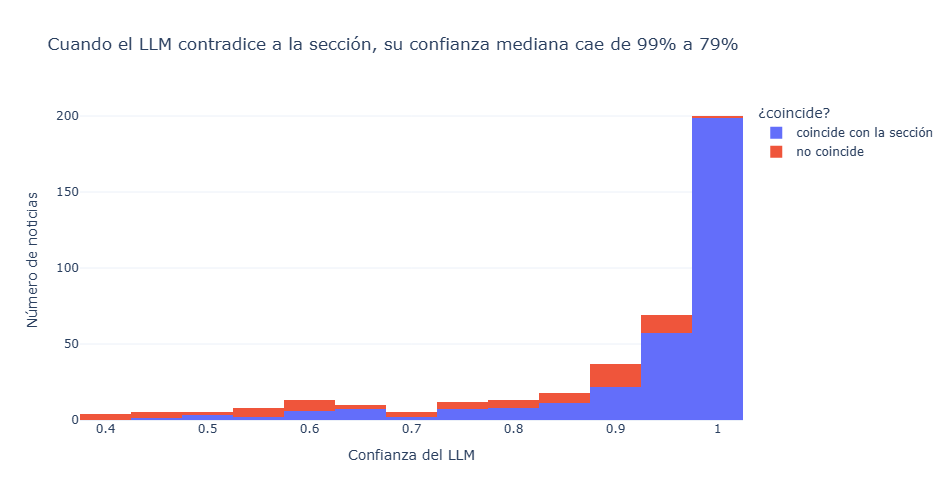

,count,mean,std,min,25%,50%,75%,max
¿coincide?,,,,,,,,
coincide con la sección,325.0,0.941,0.105,0.470,0.939,0.988,0.997,1.000
no coincide,74.0,0.750,0.178,0.385,0.593,0.793,0.904,0.983


In [11]:
df = noticias.merge(etiquetas_llm[["titular", "etiqueta_llm", "confianza"]], on="titular",
                    how="left", validate="one_to_one")
acuerdo = (df["etiqueta_llm"] == df["etiqueta"]).mean()
print(f"Acuerdo LLM vs. etiqueta editorial (dataset completo, solo descriptivo): {acuerdo:.1%}")
display(pd.crosstab(df["etiqueta"].map(LEGIBLE), df["etiqueta_llm"].map(LEGIBLE),
                    rownames=["editorial"], colnames=["LLM"], margins=True))

df["¿coincide?"] = np.where(df["etiqueta_llm"] == df["etiqueta"], "coincide con la sección",
                            "no coincide")
conf = df.groupby("¿coincide?")["confianza"].median()
titulo = (f"Cuando el LLM contradice a la sección, su confianza mediana cae de "
          f"{conf['coincide con la sección']:.0%} a {conf['no coincide']:.0%}")
fig = px.histogram(df, x="confianza", color="¿coincide?", nbins=20, barmode="stack", title=titulo,
                   labels={"confianza": "Confianza del LLM", "count": "Noticias"})
fig.update_layout(template="plotly_white", yaxis_title="Número de noticias")
fig.show()
df.groupby("¿coincide?")["confianza"].describe().round(3)

**Lectura.**

* El LLM coincide con la sección del diario en el **81,5 %** de las noticias (28,6 minutos de CPU para las 399).
* El error dominante es **Deportes → Política (30 de 100)**: notas de fútbol sobre polémicas, sanciones, el VAR o declaraciones de técnicos y dirigentes. El LLM asocia el lenguaje de conflicto e institucional con la política.
* La **confianza sí informa**: mediana de 99 % cuando coincide con la sección y de 79 % cuando no.
* La probabilidad total que el modelo pone en las cuatro palabras tiene una mediana de 43 %: el resto se reparte entre otras continuaciones posibles, y por eso la confianza se renormaliza entre las cuatro opciones.

### 2.6 · Auditoría humana: 20 predicciones al azar

Regla 3 de la sesión 5: *revisa a mano una muestra; si no revisas, el error entra en tu informe con
cara de dato*. Se sortean 20 noticias (`random_state=42`); el revisor lee titular y bajada y anota la
categoría correcta **sin mirar la respuesta del LLM** (revisión a ciegas), con una nota breve cuando
el caso es dudoso.

In [12]:
REVISION = pd.DataFrame([
    ('Mauricio Fiol: nadador peruano es suspendido ocho años por reincidir en dopaje',
     'deportes', ''),
    ('Ernesto Álvarez pide al Senado no someterse a diputados durante debate del pedido de facultades',
     'politica', ''),
    ('OPPO Reno16 a prueba: una opción para quienes priorizan la cámara y la creación de contenido',
     'ciencia_tecnologia', 'Reseña de un celular'),
    ('Produce cierra el 2026 sin segunda temporada de anchoveta y la SNP pide apoyo al Gobierno',
     'economia', 'Sector pesquero: decisión de Produce con impacto económico'),
    ("WhatsApp: ¿cómo tener los nuevos stickers de Luis 'Cuto' Guadalupe en tu teléfono?",
     'ciencia_tecnologia', 'Truco de WhatsApp, aunque el personaje sea un exfutbolista'),
    ('¿Cómo ver qué versión de bluetooth tiene tu celular y con cuántos dispositivos puedes vincularte?',
     'ciencia_tecnologia', ''),
    ('Buen Gobierno respaldará la moción de censura contra ministro del Interior, César Astudillo',
     'politica', ''),
    ('¿Cómo ahorrar energía con tu PC para que no se incremente tu recibo de luz?',
     'ciencia_tecnologia', 'Dudoso: consejo tecnológico con ángulo de gasto doméstico'),
    ('AFP: informalidad superior al 60% en ciudades del norte limita el alcance del nuevo retiro, advierte la CCL',
     'economia', ''),
    ('Franco Velazco arremetió contra Pablo Guede y Miguel Rondelli tras polémica con Universitario: "La solidaridad la vamos a ver a fin de año"',
     'deportes', ''),
    ('La Antártida se encuentra cubierta de hielo de hasta 4 km de espesor, pero no se compara en nada con lo que orbita cerca de Júpiter',
     'ciencia_tecnologia', ''),
    ('EE.UU. retira visa al juez Juan Carlos Núñez que falló a favor de Cosco, empresa china que opera el puerto de Chancay',
     'politica', 'Dudoso: sanción diplomática a un juez; el caso Chancay también es económico'),
    ('¿Buscas un celular que tome buenas fotos? Estos son los 10 teléfonos con las mejores cámaras en 2025',
     'ciencia_tecnologia', ''),
    ('Peor que Magis TV: ¿qué es Tele Latino y por qué deberías borrarlo de tu Smart TV o teléfono?',
     'ciencia_tecnologia', ''),
    ('Perú cerró su participación con una derrota: cayó 3-0 ante Argentina en la final del Sudamericano de Vóley Sub 19 2026',
     'deportes', ''),
    ('¿Samsung podrá usar AirDrop con los iPhone? Así funciona la última actualización de compatibilidad',
     'ciencia_tecnologia', ''),
    ('Más de 2 millones de jóvenes votarán por primera vez en las elecciones regionales y municipales 2026',
     'politica', ''),
    ('Movistar: Más de 100 comunidades rurales acceden a 4G',
     'economia', 'Dudoso: expansión de una telefónica; la bajada enfatiza el beneficio económico'),
    ('SUNAT registra más de S/123 mil millones en deuda tributaria, pero solo S/11.900 millones son recuperables',
     'economia', ''),
    ('Comisión de Constitución aún no tiene fecha para debatir pedido de facultades',
     'politica', '')
], columns=["titular", "etiqueta_revisor", "nota"])

auditoria = df.sample(20, random_state=42)[["titular", "bajada", "etiqueta", "etiqueta_llm", "confianza"]]
auditoria = auditoria.merge(REVISION, on="titular", how="left", validate="one_to_one")
assert auditoria["etiqueta_revisor"].isin(CATEGORIAS).all(), "Falta revisar alguna fila"

aciertos = int((auditoria["etiqueta_llm"] == auditoria["etiqueta_revisor"]).sum())
concordancia = aciertos / len(auditoria)
print(f"Concordancia LLM vs. revisión humana: {aciertos}/{len(auditoria)} = {concordancia:.0%}")
print(f"Concordancia sección del diario vs. revisión humana: "
      f"{(auditoria['etiqueta'] == auditoria['etiqueta_revisor']).sum()}/{len(auditoria)}")
auditoria.to_csv(DATOS / "auditoria_llm.csv", index=False)
auditoria[["titular", "etiqueta_revisor", "etiqueta_llm", "confianza", "etiqueta", "nota"]]

Concordancia LLM vs. revisión humana: 15/20 = 75%
Concordancia sección del diario vs. revisión humana: 20/20


,titular,etiqueta_revisor,etiqueta_llm,confianza,etiqueta,nota
0,Mauricio Fiol: nadador peruano es suspendido ocho años por reincidir en dopaje,deportes,politica,0.7774,deportes,
1,Ernesto Álvarez pide al Senado no someterse a diputados durante debate del pedido de facultades,politica,politica,0.9950,politica,
2,OPPO Reno16 a prueba: una opción para quienes priorizan la cámara y la creación de contenido,ciencia_tecnologia,ciencia_tecnologia,0.5164,ciencia_tecnologia,Reseña de un celular
3,Produce cierra el 2026 sin segunda temporada de anchoveta y la SNP pide apoyo al Gobierno,economia,economia,0.7566,economia,Sector pesquero: decisión de Produce con impacto económico
4,WhatsApp: ¿cómo tener los nuevos stickers de Luis 'Cuto' Guadalupe en tu teléfono?,ciencia_tecnologia,ciencia_tecnologia,0.9901,ciencia_tecnologia,"Truco de WhatsApp, aunque el personaje sea un exfutbolista"
5,¿Cómo ver qué versión de bluetooth tiene tu celular y con cuántos dispositivos puedes vincularte?,ciencia_tecnologia,ciencia_tecnologia,0.9891,ciencia_tecnologia,
6,"Buen Gobierno respaldará la moción de censura contra ministro del Interior, César Astudillo",politica,politica,0.9915,politica,
7,¿Cómo ahorrar energía con tu PC para que no se incremente tu recibo de luz?,ciencia_tecnologia,economia,0.9324,ciencia_tecnologia,Dudoso: consejo tecnológico con ángulo de gasto doméstico
8,"AFP: informalidad superior al 60% en ciudades del norte limita el alcance del nuevo retiro, advi...",economia,economia,0.8692,economia,
9,"Franco Velazco arremetió contra Pablo Guede y Miguel Rondelli tras polémica con Universitario: ""...",deportes,politica,0.4215,deportes,


In [13]:
desacuerdos = auditoria[auditoria["etiqueta_llm"] != auditoria["etiqueta_revisor"]]
desacuerdos[["titular", "bajada", "etiqueta_revisor", "etiqueta_llm", "confianza", "nota"]]

,titular,bajada,etiqueta_revisor,etiqueta_llm,confianza,nota
0,Mauricio Fiol: nadador peruano es suspendido ocho años por reincidir en dopaje,El medallista peruano Mauricio Fiol recibió una duro castigo por parte de la Federación Internac...,deportes,politica,0.7774,
7,¿Cómo ahorrar energía con tu PC para que no se incremente tu recibo de luz?,"Si usas tu computadora todos los días y por muchas horas, entonces debes tomar en cuenta las sig...",ciencia_tecnologia,economia,0.9324,Dudoso: consejo tecnológico con ángulo de gasto doméstico
9,"Franco Velazco arremetió contra Pablo Guede y Miguel Rondelli tras polémica con Universitario: ""...","El administrador de Universitario cuestionó los procesos concursales de Alianza Lima y Melgar, d...",deportes,politica,0.4215,
16,Más de 2 millones de jóvenes votarán por primera vez en las elecciones regionales y municipales ...,"Más de 2,3 millones de ciudadanos que recién alcanzaron la mayoría de edad o la cumplirán el mis...",politica,economia,0.5562,
17,Movistar: Más de 100 comunidades rurales acceden a 4G,Esta conectividad permite a sus residentes acceder a servicios financieros y mejorar la comercia...,economia,deportes,0.3852,Dudoso: expansión de una telefónica; la bajada enfatiza el beneficio económico


**Concordancia LLM vs. revisión humana: 15/20 = 75 %.** Los 5 desacuerdos:

* **2 notas deportivas con conflicto institucional** (suspensión por dopaje de Mauricio Fiol; pelea entre el administrador de Universitario y técnicos rivales) que el LLM manda a política: el mismo patrón de la tabla anterior.
* **1 nota electoral** (nuevos votantes en las elecciones regionales) que el LLM manda a economía.
* **2 casos que el propio revisor marcó como dudosos**: el ahorro de energía del PC (tecnología con ángulo de gasto) y la ampliación de la red 4G de Movistar, que el LLM manda a deportes con baja confianza (39 %).

En las 20 noticias, la sección del diario coincidió con el revisor: la etiqueta editorial es una buena vara de medir.

## 3 · Partición estratificada 70 / 15 / 15

Se estratifica por la etiqueta editorial para que las tres partes tengan la misma mezcla de
categorías. **Desde aquí, `test` no se toca hasta la sección 5.**

In [14]:
train, resto = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=42)
val, test = train_test_split(resto, test_size=0.50, stratify=resto["etiqueta"], random_state=42)

assert not (set(train["url"]) & set(test["url"]) or set(val["url"]) & set(test["url"]))
assert set(train["url"]) == set(train_dev["url"])     # la misma partición usada en 2.4
particion = pd.concat([train.assign(particion="train"), val.assign(particion="val"),
                       test.assign(particion="test")])
particion[["url", "particion"]].to_csv(DATOS / "particion.csv", index=False)

for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre:<5} {len(parte):>4} noticias ({len(parte) / len(df):.1%})")
tabla = pd.crosstab(particion["etiqueta"], particion["particion"])[["train", "val", "test"]]
tabla.loc["TOTAL"] = tabla.sum()
tabla

train  279 noticias (69.9%)
val     60 noticias (15.0%)
test    60 noticias (15.0%)


particion,train,val,test
etiqueta,,,
ciencia_tecnologia,69,15,15
deportes,70,15,15
economia,70,15,15
politica,70,15,15
TOTAL,279,60,60


**Qué etiqueta usa cada parte:**

| Parte | Etiqueta | Para qué |
|---|---|---|
| train | `etiqueta_llm` (supervisión débil) | Ajustar los pesos del Transformer |
| val | `etiqueta` (editorial) | Elegir la mejor época y el mejor modelo base |
| test | `etiqueta` (editorial) | Medir **una sola vez**, al final |

In [15]:
ruido = (train["etiqueta_llm"] != train["etiqueta"]).mean()
print(f"En train, el {ruido:.1%} de las etiquetas del LLM difiere de la sección del diario: "
      "ese es el «ruido» con el que aprende el modelo.")
train["etiqueta_llm"].value_counts()

En train, el 17.6% de las etiquetas del LLM difiere de la sección del diario: ese es el «ruido» con el que aprende el modelo.


etiqueta_llm
politica              94
economia              70
ciencia_tecnologia    63
deportes              52
Name: count, dtype: int64

El sesgo del maestro se ve directo en la distribución: el LLM etiqueta como Política **94** noticias de train cuando la sección dice 70, y solo 52 como Deportes. De las 70 noticias deportivas de train, **22 llegan al entrenamiento con la etiqueta «politica»**.

## 4 · Fine-tuning de un Transformer

Se comparan los dos modelos recomendados con **la misma configuración** y se elige por F1 macro en
**validación** (nunca en test). Como se dijo en la clase de fine-tuning: para defender un
clasificador hay que probar varios y quedarse con el mejor.

| Modelo | Idioma | Capas | Parámetros |
|---|---|---|---|
| `distilbert-base-multilingual-cased` | 104 idiomas | 6 | ~135 M |
| `dccuchile/bert-base-spanish-wwm-cased` (BETO) | español | 12 | ~110 M |

Configuración (`HuggingFace Trainer`): 3 épocas, batch de 16, evaluación por época, métrica de
optimización **F1 macro** (`sklearn.metrics.f1_score(average="macro")`) y se conserva la mejor época.
Entrada: **solo el titular** (máximo 64 tokens), porque eso es lo que recibirá el dashboard.

In [16]:
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}

def a_dataset(tabla, columna_etiqueta, tokenizer):
    ds = Dataset.from_dict({"text": tabla["titular"].tolist(),
                            "labels": tabla[columna_etiqueta].map(label2id).tolist()})
    return ds.map(lambda lote: tokenizer(lote["text"], truncation=True, max_length=64),
                  batched=True, remove_columns=["text"])

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, pred),
            "f1_macro": f1_score(labels, pred, average="macro")}

def entrenar(modelo_base, carpeta):
    set_seed(42)
    tokenizer = AutoTokenizer.from_pretrained(modelo_base)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        modelo_base, num_labels=len(CATEGORIAS), id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=carpeta,
        num_train_epochs=3,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=5e-5,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        save_only_model=True,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        logging_strategy="epoch",
        report_to="none",
        seed=42,
        disable_tqdm=True,
        use_cpu=True,
    )
    trainer = Trainer(
        model=modelo,
        args=args,
        train_dataset=a_dataset(train, "etiqueta_llm", tokenizer),
        eval_dataset=a_dataset(val, "etiqueta", tokenizer),
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )
    inicio = time.perf_counter()
    trainer.train()
    minutos = (time.perf_counter() - inicio) / 60
    historia = pd.DataFrame(trainer.state.log_history)
    por_epoca = (historia.groupby("epoch")
                 .agg(loss_train=("loss", "first"), loss_val=("eval_loss", "first"),
                      accuracy_val=("eval_accuracy", "first"), f1_macro_val=("eval_f1_macro", "first"))
                 .dropna(how="all").round(4))
    return trainer, tokenizer, por_epoca, minutos

In [17]:
CANDIDATOS = {
    "DistilBERT multilingüe": "distilbert-base-multilingual-cased",
    "BETO": "dccuchile/bert-base-spanish-wwm-cased",
}
entrenados, resumen = {}, []
for nombre, base in CANDIDATOS.items():
    trainer, tokenizer, por_epoca, minutos = entrenar(base, f"_entrenamiento/{base.split('/')[-1]}")
    entrenados[nombre] = (trainer, tokenizer)
    print(f"\n■ {nombre} ({base}) · {minutos:.1f} min en CPU")
    display(por_epoca)
    resumen.append({"modelo": nombre, "base": base, "minutos_cpu": round(minutos, 1),
                    "f1_macro_val (mejor época)": por_epoca["f1_macro_val"].max(),
                    "params_M": round(trainer.model.num_parameters() / 1e6)})

resumen = pd.DataFrame(resumen).sort_values("f1_macro_val (mejor época)", ascending=False)
resumen

{'loss': '1.183', 'grad_norm': '5.903', 'learning_rate': '3.426e-05', 'epoch': '1'}


{'eval_loss': '0.8024', 'eval_accuracy': '0.8167', 'eval_f1_macro': '0.8163', 'eval_runtime': '1.254', 'eval_samples_per_second': '47.85', 'eval_steps_per_second': '1.595', 'epoch': '1'}


{'loss': '0.6083', 'grad_norm': '9.669', 'learning_rate': '1.759e-05', 'epoch': '2'}


{'eval_loss': '0.6497', 'eval_accuracy': '0.7833', 'eval_f1_macro': '0.7839', 'eval_runtime': '1.275', 'eval_samples_per_second': '47.07', 'eval_steps_per_second': '1.569', 'epoch': '2'}


{'loss': '0.3766', 'grad_norm': '2.276', 'learning_rate': '9.259e-07', 'epoch': '3'}


...

{'eval_loss': '0.6444', 'eval_accuracy': '0.8', 'eval_f1_macro': '0.8037', 'eval_runtime': '2.415', 'eval_samples_per_second': '24.85', 'eval_steps_per_second': '0.828', 'epoch': '3'}


{'train_runtime': '149.9', 'train_samples_per_second': '5.585', 'train_steps_per_second': '0.36', 'train_loss': '0.5208', 'epoch': '3'}



■ BETO (dccuchile/bert-base-spanish-wwm-cased) · 2.5 min en CPU


,loss_train,loss_val,accuracy_val,f1_macro_val
epoch,,,,
1.0,0.9772,0.6202,0.8167,0.8188
2.0,0.3948,0.6309,0.7833,0.7859
3.0,0.1905,0.6444,0.8000,0.8037


,modelo,base,minutos_cpu,f1_macro_val (mejor época),params_M
1,BETO,dccuchile/bert-base-spanish-wwm-cased,2.5,0.8188,110
0,DistilBERT multilingüe,distilbert-base-multilingual-cased,1.5,0.8163,135


**Lectura.** Los dos modelos alcanzan su mejor F1 en validación en la **primera época** y después empeoran, mientras la pérdida de train sigue bajando (BETO: 0,98 → 0,19). Es la firma de aprender con etiquetas ruidosas: tras captar el patrón general, el modelo empieza a **memorizar los errores del LLM**. `load_best_model_at_end=True` conserva la época 1, elegida con etiquetas editoriales de validación: ahí se complementan la supervisión débil (train) y la editorial (val).

BETO gana por un margen mínimo (0,819 vs. 0,816 en 60 noticias, menos de un titular), así que la elección también se apoya en que es un modelo nativo en español. A cambio, tarda un poco más (2,5 vs. 1,5 min).

In [18]:
ELEGIDO = resumen.iloc[0]["modelo"]
trainer, tokenizer = entrenados[ELEGIDO]
print(f"Modelo elegido por F1 macro en validación: {ELEGIDO} ({CANDIDATOS[ELEGIDO]})")

trainer.save_model(MODELO)
tokenizer.save_pretrained(MODELO)
shutil.rmtree("_entrenamiento", ignore_errors=True)      # checkpoints intermedios: no se versionan

for f in sorted(MODELO.iterdir()):
    print(f"   {f.name:<28} {f.stat().st_size / 1e6:8.1f} MB")

Modelo elegido por F1 macro en validación: BETO (dccuchile/bert-base-spanish-wwm-cased)


   config.json                       0.0 MB
   model.safetensors               439.4 MB
   tokenizer.json                    0.7 MB
   tokenizer_config.json             0.0 MB
   training_args.bin                 0.0 MB


Los pesos (`model.safetensors`) pesan cientos de MB: quedan fuera de Git por el `.gitignore`. Lo
liviano (configuración, tokenizador y métricas) sí se versiona.

## 5 · Evaluación final en test

Primera y única vez que se usa `test`.

In [19]:
ds_test = a_dataset(test, "etiqueta", tokenizer)
salida = trainer.predict(ds_test)
probs_test = torch.softmax(torch.tensor(salida.predictions), dim=-1).numpy()
test = test.assign(pred_ft=[id2label[i] for i in probs_test.argmax(1)],
                   prob_ft=probs_test.max(1))

final = metricas(test["etiqueta"], test["pred_ft"])
print(f"{ELEGIDO} en TEST (n = {len(test)}) → accuracy = {final['accuracy']:.3f} · "
      f"F1 macro = {final['f1_macro']:.3f}\n")
print(classification_report(test["etiqueta"], test["pred_ft"], labels=CATEGORIAS, digits=3))

BETO en TEST (n = 60) → accuracy = 0.883 · F1 macro = 0.883

                    precision    recall  f1-score   support

          politica      0.778     0.933     0.848        15
          economia      0.875     0.933     0.903        15
          deportes      1.000     0.733     0.846        15
ciencia_tecnologia      0.933     0.933     0.933        15

          accuracy                          0.883        60
         macro avg      0.897     0.883     0.883        60
      weighted avg      0.897     0.883     0.883        60



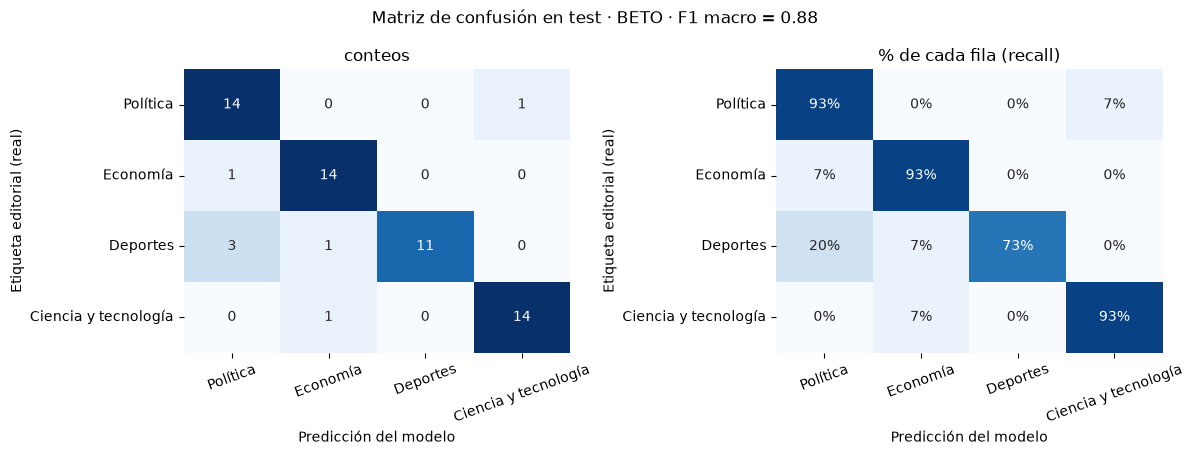

In [20]:
cm = confusion_matrix(test["etiqueta"], test["pred_ft"], labels=CATEGORIAS)
nombres = [LEGIBLE[c] for c in CATEGORIAS]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ejes[0],
            xticklabels=nombres, yticklabels=nombres)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".0%", cmap="Blues", cbar=False,
            ax=ejes[1], xticklabels=nombres, yticklabels=nombres, vmin=0, vmax=1)
for eje, sub in zip(ejes, ["conteos", "% de cada fila (recall)"]):
    eje.set_xlabel("Predicción del modelo")
    eje.set_ylabel("Etiqueta editorial (real)")
    eje.set_title(sub)
    eje.tick_params(axis="x", rotation=20)
fig.suptitle(f"Matriz de confusión en test · {ELEGIDO} · F1 macro = {final['f1_macro']:.2f}", fontsize=12)
plt.tight_layout()
plt.show()

In [21]:
por_categoria = pd.DataFrame(classification_report(test["etiqueta"], test["pred_ft"], labels=CATEGORIAS,
                                                   output_dict=True)).T.loc[CATEGORIAS]
por_categoria = por_categoria.rename(index=LEGIBLE).round(3).sort_values("f1-score", ascending=False)
display(por_categoria)

errores = test[test["pred_ft"] != test["etiqueta"]]
print(f"Errores en test: {len(errores)} de {len(test)}")
errores[["titular", "etiqueta", "pred_ft", "prob_ft", "etiqueta_llm"]].sort_values("etiqueta")

,precision,recall,f1-score,support
Ciencia y tecnología,0.933,0.933,0.933,15.0
Economía,0.875,0.933,0.903,15.0
Política,0.778,0.933,0.848,15.0
Deportes,1.000,0.733,0.846,15.0


Errores en test: 7 de 60


,titular,etiqueta,pred_ft,prob_ft,etiqueta_llm
92,"Sony Ericcson, LG y otras marcas de celulares que desaparecieron del mercado",ciencia_tecnologia,economia,0.423636,ciencia_tecnologia
105,Pablo Guede expone el preocupante estado de Esteban Pávez tras salir lesionado ante Atlético Gra...,deportes,politica,0.570203,politica
106,"Pablo Guede ningunea a Franco Velazco, administrador de Universitario, tras polémicas declaracio...",deportes,politica,0.733359,politica
193,"¿Cuánto pagó el 5y6 La Rinconada del domingo 18 de agosto? Monto sellado, cuadros con 6 aciertos...",deportes,economia,0.765711,economia
142,"Mamá de Cristiano Ronaldo envía duro mensaje contra Portugal: ""No lo valoran, es el pueblo que t...",deportes,politica,0.624727,politica
209,Movistar prepara su red en Lambayeque ante posibles emergencias por el Fenómeno El Niño,economia,politica,0.415055,ciencia_tecnologia
384,"Sheput alerta un millón y medio de ""ninis"" para justificar facultades: ""¿Qué derecho le vamos a ...",politica,ciencia_tecnologia,0.604237,politica


### Reflexión por categoría

**4 de los 7 errores del modelo en test son exactamente los del LLM** que lo entrenó: el estudiante hereda los sesgos del maestro.

* **Mejor desempeño: Ciencia y tecnología (F1 0,933).** Tiene un vocabulario propio que casi no comparte con las otras secciones (*celular, WhatsApp, app, científicos, NASA, especie, fósil*), y muchas notas siguen una plantilla de servicio («¿Cómo…?», «Así puedes…») fácil de reconocer. Su único error es *«Sony Ericcson, LG y otras marcas de celulares que desaparecieron del mercado»*: *marcas* y *mercado* son palabras de economía.
* **Economía (F1 0,903).** Le va bien pese a compartir actores con la política, porque una parte de sus notas es casi una plantilla (precio del dólar, AFP). Su error, *«Movistar prepara su red en Lambayeque ante posibles emergencias por el Fenómeno El Niño»*, es temáticamente ambiguo (empresa + emergencia + región): tampoco el LLM lo puso en economía.
* **Política (F1 0,848).** Recall alto (14/15) pero la precisión más baja (0,778): funciona como **«sumidero»** de las notas con conflicto, declaraciones o autoridades, aunque sean de otra sección. Recibe 3 notas deportivas y 1 económica.
* **Peor desempeño: Deportes (F1 0,846; recall 0,733).** Es una paradoja: el vocabulario deportivo es el más fácil (el zero-shot acertó 9 de 10), pero el modelo aprendió del sesgo del maestro, que le pasó 22 notas deportivas como política. Los 4 errores en test son notas **sin acción deportiva**: la polémica entre Pablo Guede y el administrador de Universitario, el parte médico de un jugador, la madre de Cristiano Ronaldo criticando a Portugal (*«es el pueblo que tenemos»*) y los pagos de la apuesta hípica 5y6 (*«¿Cuánto pagó…? Monto…»*, que el modelo lleva a economía porque gana el léxico del dinero).

  **Causa lingüística:** los verbos de confrontación (*ningunea, arremete, envía duro mensaje*) y los sustantivos institucionales (*administrador, sanción, pueblo*) son los mismos de la cobertura política. Aun así, en deportes **el estudiante supera al maestro**: recall de 0,733 frente a 0,533 del LLM en el mismo test, Una explicación plausible: los nombres más frecuentes llegan a train mayormente bien etiquetados (*Alianza*: 13 de 17 con «deportes»; *Universitario*: 10 de 15; *Vóley*: 12 de 12), y la época se eligió con etiquetas editoriales de validación, antes de que el modelo memorizara el ruido.

## 6 · Comparativa y decisión

Los tres enfoques se miden **en el mismo test** contra la etiqueta editorial. Se agrega como
referencia un clasificador clásico (TF-IDF + regresión logística) entrenado con las mismas etiquetas
del LLM: pesa unos cientos de KB y es el respaldo que usa el dashboard cuando los pesos del
Transformer no están disponibles (por ejemplo, al clonar el repositorio, porque no se suben a
GitHub).

La latencia se mide clasificando titulares **de a uno**, como ocurriría en el dashboard.

In [22]:
# Zero-shot sobre el test completo
test["pred_zs"], _ = clasificar_zero_shot(test["titular"])

# TF-IDF + regresión logística con las mismas etiquetas débiles de train
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, strip_accents="unicode"),
                      LogisticRegression(C=10, max_iter=3000))
tfidf.fit(train["titular"], train["etiqueta_llm"])
test["pred_tfidf"] = tfidf.predict(test["titular"])
joblib.dump(tfidf, MODELO / "tfidf_logreg.joblib")

clasificador = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=-1)

def latencia_ms(funcion, textos):
    inicio = time.perf_counter()
    for t in textos:
        funcion(t)
    return (time.perf_counter() - inicio) / len(textos) * 1000

muestra_lat = test.head(20)
lat = {
    "zs": latencia_ms(lambda t: clasificar_zero_shot([t]), muestra_lat["titular"]),
    "llm": seg_llm * 1000,                       # medido al etiquetar las ~400 noticias (2.5)
    "ft": latencia_ms(lambda t: clasificador(t), muestra_lat["titular"]),
    "tfidf": latencia_ms(lambda t: tfidf.predict([t]), muestra_lat["titular"]),
}
print({k: f"{v:.0f} ms" for k, v in lat.items()})

{'zs': '233 ms', 'llm': '4295 ms', 'ft': '51 ms', 'tfidf': '2 ms'}


In [23]:
def fila(enfoque, modelo, entrada, pred, latencia, params, aprende):
    m = metricas(test["etiqueta"], pred)
    return {"enfoque": enfoque, "modelo": modelo, "entrada": entrada,
            "accuracy_test": round(m["accuracy"], 3), "f1_macro_test": round(m["f1_macro"], 3),
            "latencia_ms_por_titular_cpu": round(latencia), "parametros": params,
            "¿entrena con nuestros datos?": aprende}

n_ft = trainer.model.num_parameters() / 1e6
n_zs = zero_shot.model.num_parameters() / 1e6
n_llm = sum(p.numel() for p in llm.parameters()) / 1e6
comparativa = pd.DataFrame([
    fila("1 · Zero-shot (piso)", MODELO_ZS, "titular", test["pred_zs"], lat["zs"], f"{n_zs:,.0f} M", "no"),
    fila("2 · LLM débil (maestro)", MODELO_LLM, "titular + bajada", test["etiqueta_llm"], lat["llm"],
         f"{n_llm:,.0f} M", "no"),
    fila("3 · Transformer fine-tuned", f"{ELEGIDO} ({CANDIDATOS[ELEGIDO]})", "titular",
         test["pred_ft"], lat["ft"], f"{n_ft:,.0f} M", "sí (etiquetas del LLM)"),
    fila("Extra · TF-IDF + reg. logística", "scikit-learn", "titular", test["pred_tfidf"], lat["tfidf"],
         "<1 M", "sí (etiquetas del LLM)"),
])
print(f"Test: {len(test)} noticias. Con n tan chico, 1 titular ≈ {1 / len(test):.1%} de accuracy.")
comparativa

Test: 60 noticias. Con n tan chico, 1 titular ≈ 1.7% de accuracy.


,enfoque,modelo,entrada,accuracy_test,f1_macro_test,latencia_ms_por_titular_cpu,parametros,¿entrena con nuestros datos?
0,1 · Zero-shot (piso),Recognai/bert-base-spanish-wwm-cased-xnli,titular,0.617,0.592,233,110 M,no
1,2 · LLM débil (maestro),Qwen/Qwen2.5-1.5B-Instruct,titular + bajada,0.800,0.792,4295,"1,544 M",no
2,3 · Transformer fine-tuned,BETO (dccuchile/bert-base-spanish-wwm-cased),titular,0.883,0.883,51,110 M,sí (etiquetas del LLM)
3,Extra · TF-IDF + reg. logística,scikit-learn,titular,0.800,0.789,2,<1 M,sí (etiquetas del LLM)


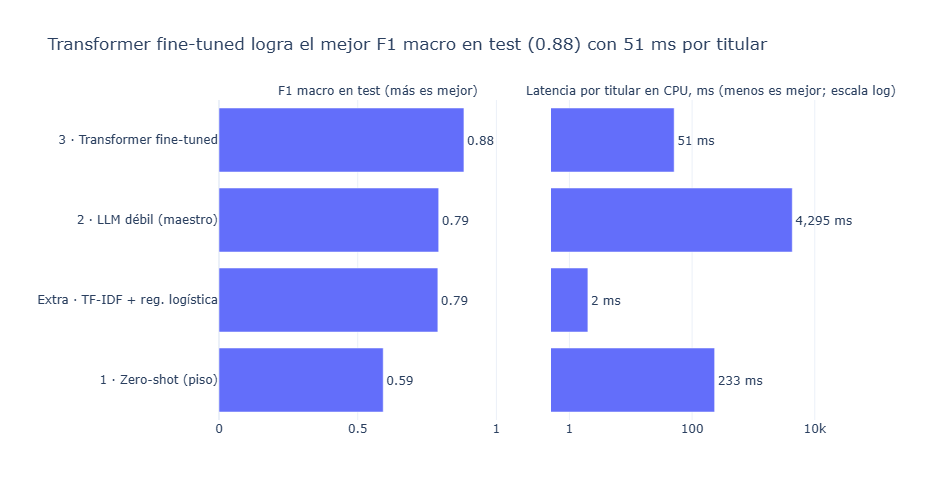

In [24]:
mejor = comparativa.loc[comparativa["f1_macro_test"].idxmax()]
titulo = (f"{mejor['enfoque'].split('· ')[-1]} logra el mejor F1 macro en test ({mejor['f1_macro_test']:.2f}) "
          f"con {mejor['latencia_ms_por_titular_cpu']:,.0f} ms por titular")
largo = comparativa.melt(id_vars="enfoque", value_vars=["f1_macro_test", "latencia_ms_por_titular_cpu"],
                         var_name="metrica", value_name="valor")
largo["metrica"] = largo["metrica"].map({
    "f1_macro_test": "F1 macro en test (más es mejor)",
    "latencia_ms_por_titular_cpu": "Latencia por titular en CPU, ms (menos es mejor; escala log)"})
orden = comparativa.sort_values("f1_macro_test", ascending=False)["enfoque"].tolist()
fig = px.bar(largo, x="valor", y="enfoque", facet_col="metrica", orientation="h", text="valor",
             category_orders={"enfoque": orden}, title=titulo, labels={"valor": "", "enfoque": ""})
fig.update_xaxes(matches=None)
fig.update_xaxes(type="log", range=[-0.3, 4.9], col=2)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
for traza in fig.data:
    traza.texttemplate = "%{x:.2f}" if traza.xaxis == "x" else "%{x:,.0f} ms"
    traza.textposition = "outside"
fig.update_xaxes(range=[0, 1.15], col=1)
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

In [25]:
descarga = json.loads((DATOS / "raw" / "metadatos_descarga.json").read_text(encoding="utf-8"))
resumen_metricas = {
    "fecha": date.today().isoformat(),
    "fecha_descarga": descarga["fecha_descarga"][:10],
    "n_noticias": int(len(df)),
    "n_train": int(len(train)), "n_val": int(len(val)), "n_test": int(len(test)),
    "modelo_elegido": ELEGIDO, "modelo_base": CANDIDATOS[ELEGIDO],
    "accuracy_test": round(final["accuracy"], 4), "f1_macro_test": round(final["f1_macro"], 4),
    "zero_shot_40": {"modelo": MODELO_ZS, **{k: round(v, 4) for k, v in base_zs.items()}},
    "llm": {"modelo": MODELO_LLM, "acuerdo_editorial_total": round(acuerdo, 4),
            "concordancia_auditoria": round(concordancia, 4), "aciertos_auditoria": aciertos,
            "n_auditoria": int(len(auditoria))},
    "comparativa_test": comparativa.to_dict(orient="records"),
}
(MODELO / "metricas.json").write_text(json.dumps(resumen_metricas, ensure_ascii=False, indent=2),
                                      encoding="utf-8")
print(json.dumps({k: v for k, v in resumen_metricas.items() if k != "comparativa_test"},
                 ensure_ascii=False, indent=1))

{
 "fecha": "2026-10-18",
 "fecha_descarga": "2026-10-18",
 "n_noticias": 399,
 "n_train": 279,
 "n_val": 60,
 "n_test": 60,
 "modelo_elegido": "BETO",
 "modelo_base": "dccuchile/bert-base-spanish-wwm-cased",
 "accuracy_test": 0.8833,
 "f1_macro_test": 0.8828,
 "zero_shot_40": {
  "modelo": "Recognai/bert-base-spanish-wwm-cased-xnli",
  "accuracy": 0.7,
  "f1_macro": 0.6968
 },
 "llm": {
  "modelo": "Qwen/Qwen2.5-1.5B-Instruct",
  "acuerdo_editorial_total": 0.8145,
  "concordancia_auditoria": 0.75,
  "aciertos_auditoria": 15,
  "n_auditoria": 20
 }
}


### Decisión

| Criterio | Zero-shot | LLM débil | **Fine-tuned (BETO)** | TF-IDF (extra) |
|---|---|---|---|---|
| F1 macro en test | 0,59 | 0,79 | **0,88** | 0,79 |
| Latencia por titular (CPU) | 233 ms | 4 295 ms | **51 ms** | 2 ms |
| Parámetros | 110 M | 1 544 M | 110 M | < 1 M |
| ¿Necesita etiquetas? | no | no | sí (las del LLM) | sí (las del LLM) |

**Para un entorno real elegiría el Transformer fine-tuned (BETO):**

1. **Precisión.** Tiene el mejor F1 macro en test (0,88): 9 puntos más que su maestro y 29 más que el zero-shot. Frente al LLM son ~5 titulares más acertados de 60, no un caso suelto.
2. **Costo computacional.** Tiene 14 veces menos parámetros que el LLM y corre en la CPU de una laptop. Entrenarlo costó 2,5 min; lo caro fue etiquetar (28,6 min de LLM), y eso se paga **una sola vez**.
3. **Latencia.** 51 ms por titular frente a 4,3 s del LLM (≈ 84 veces más rápido). Es lo que permite clasificar en vivo en el dashboard.

**El papel de los demás.** El LLM queda como **etiquetador fuera de línea**, no como clasificador en producción. El TF-IDF es el **plan B** cuando no caben los pesos del Transformer (2 ms y < 1 MB), aceptando ~9 puntos menos de F1; es el respaldo que usa el dashboard. El zero-shot sirve solo para arrancar sin ningún dato.

**Cautelas.**

* El test es pequeño (60 noticias, 15 por categoría): cada titular mueve ~1,7 puntos de accuracy.
* El modelo hereda el sesgo Deportes → Política del LLM. La mejora más barata sería corregir a mano las etiquetas deportivas que el LLM mandó a política (o descartar las de baja confianza) antes de reentrenar.

## Lo que hicimos

| Paso | Herramienta | Resultado |
|---|---|---|
| Piso sin entrenamiento | `pipeline("zero-shot-classification")` | accuracy y F1 macro en 40 titulares |
| Etiquetas baratas | Qwen2.5-1.5B local, prompt cerrado, probabilidad de cada palabra (regla de la cadena) | `datos/etiquetas_llm.csv` |
| Control de calidad | Auditoría a ciegas de 20 casos | % de concordancia |
| Partición | `train_test_split` estratificado ×2, `random_state=42` | `datos/particion.csv` |
| Fine-tuning | `Trainer`, 3 épocas, batch 16, F1 macro, 2 modelos base | `modelo/` |
| Evaluación | Test aislado + matriz de confusión (`seaborn`) | `modelo/metricas.json` |